In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

# Part 1 - Product Categories

In [6]:
category_freq = df["category"].value_counts()

category_freq.head()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [7]:
top_5_categories = df["category"].value_counts().head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

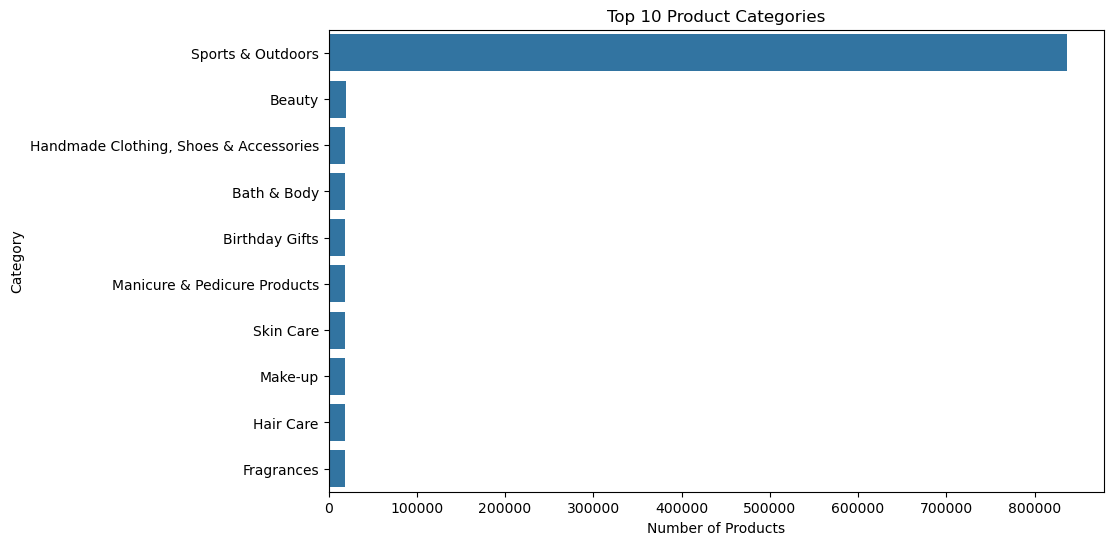

In [8]:
top_10 = df["category"].value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_10.values,
    y=top_10.index
)

plt.title("Top 10 Product Categories")
plt.xlabel("Number of Products")
plt.ylabel("Category")

plt.show()

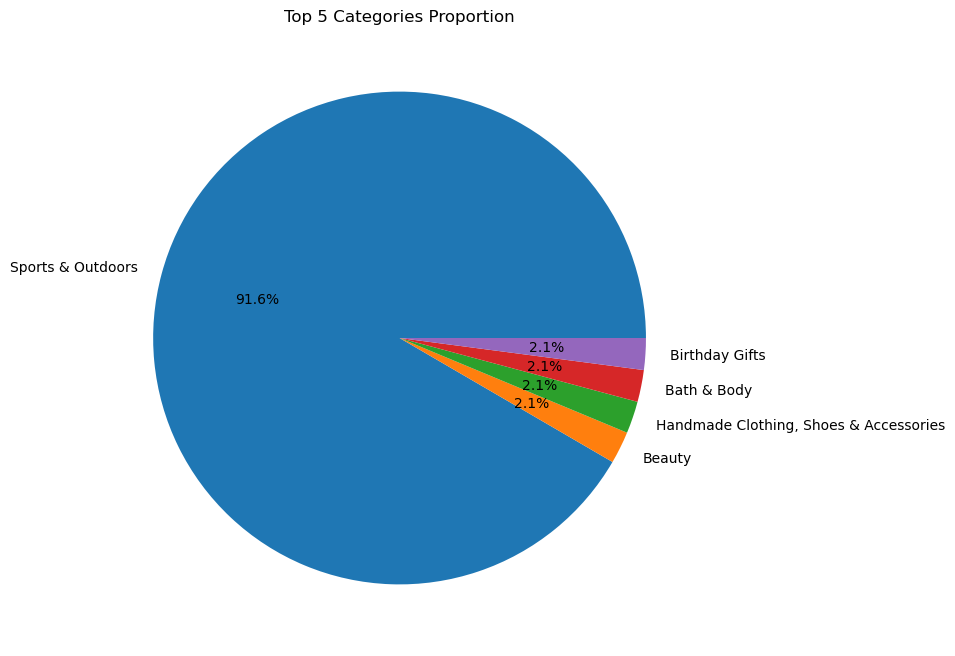

In [9]:
top_5 = df["category"].value_counts().head(5)

plt.figure(figsize=(8,8))

plt.pie(
    top_5.values,
    labels=top_5.index,
    autopct='%1.1f%%'
)

plt.title("Top 5 Categories Proportion")

plt.show()

The category “X” dominates the listings, suggesting high product availability and competition in this segment.

# PART 2 → Prices

In [10]:
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

print("Mean:", mean_price)
print("Median:", median_price)
print("Mode:", mode_price)

Mean: 89.24380943923661
Median: 19.09
Mode: 9.99


In [11]:
df["price"].var()

119445.48532256528

In [12]:
df["price"].std()

345.60886175352226

In [13]:
df["price"].max() - df["price"].min()

100000.0

In [14]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)

iqr = q3 - q1

iqr

np.float64(36.0)

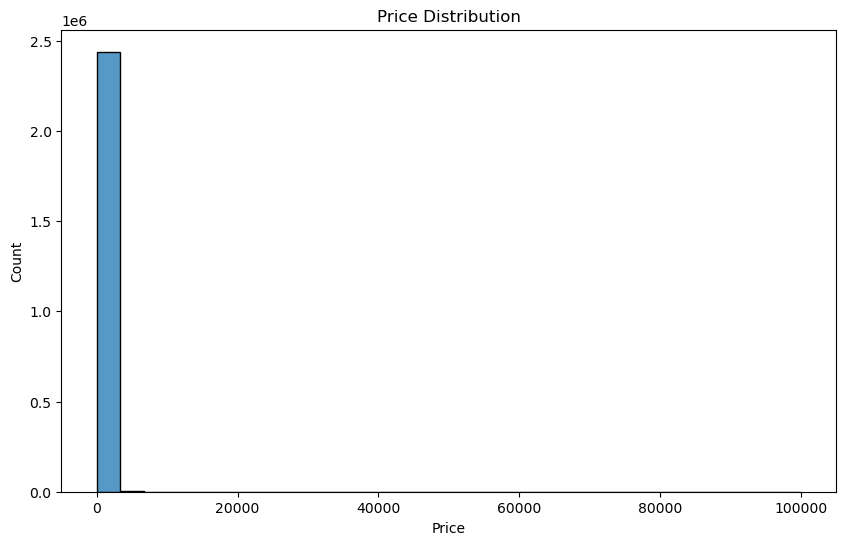

In [15]:
plt.figure(figsize=(10,6))

sns.histplot(df["price"], bins=30)

plt.title("Price Distribution")
plt.xlabel("Price")

plt.show()

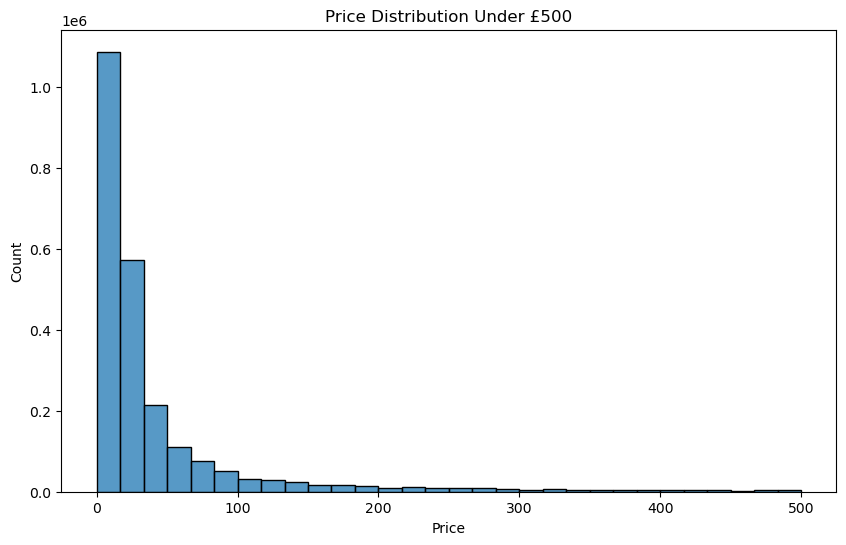

In [16]:
plt.figure(figsize=(10,6))

sns.histplot(df[df["price"] < 500]["price"], bins=30)

plt.title("Price Distribution Under £500")
plt.xlabel("Price")

plt.show()

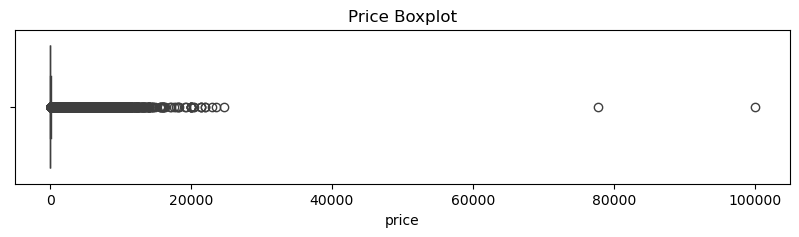

In [17]:
plt.figure(figsize=(10,2))

sns.boxplot(x=df["price"])

plt.title("Price Boxplot")

plt.show()

The histogram is difficult to interpret because a small number of extremely expensive products stretch the scale of the distribution.

Most products are concentrated in the lower price ranges, while a few extreme outliers significantly increase the maximum price.

The distribution is highly right-skewed, with several expensive outliers significantly above the average price.

# Part 3 — Ratings

In [18]:
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print(mean_rating)
print(median_rating)
print(mode_rating)

2.152836472966066
0.0
0.0


In [19]:
ratings = df[df["stars"] > 0]

In [20]:
mean_rating = ratings["stars"].mean()
median_rating = ratings["stars"].median()
mode_rating = ratings["stars"].mode()[0]

print(mean_rating)
print(median_rating)
print(mode_rating)

4.319160762226911
4.4
4.5


After removing products with 0-star ratings, the average product rating increased significantly to 4.32 stars.

This suggests that most reviewed products on Amazon UK receive highly positive customer feedback. The most frequent rating is 4.5 stars, indicating a strong tendency toward customer satisfaction.

In [21]:
variance = ratings["stars"].var()
std_dev = ratings["stars"].std()

q1 = ratings["stars"].quantile(0.25)
q3 = ratings["stars"].quantile(0.75)

iqr = q3 - q1

print("Variance:", variance)
print("Standard Deviation:", std_dev)
print("IQR:", iqr)

Variance: 0.3083433752380519
Standard Deviation: 0.5552867504614637
IQR: 0.5


In [22]:
print(ratings["stars"].skew())
print(ratings["stars"].kurtosis())

-2.379568112212799
9.78193769066435


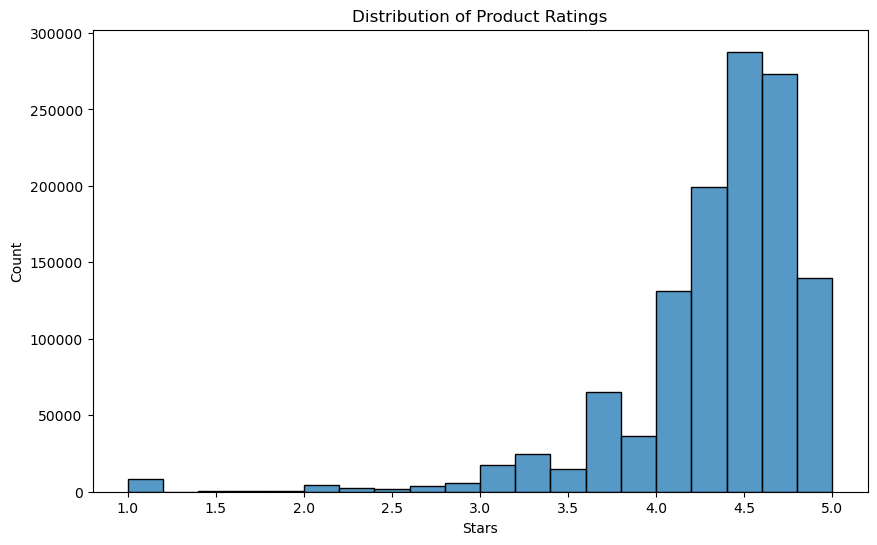

In [23]:
plt.figure(figsize=(10,6))

sns.histplot(ratings["stars"], bins=20)

plt.title("Distribution of Product Ratings")
plt.xlabel("Stars")

plt.show()

The ratings distribution is strongly concentrated between 4 and 5 stars, indicating generally high customer satisfaction across Amazon UK products.

The negative skewness (-2.37) shows that most products receive high ratings, while only a small number of products have low scores.

Additionally, the high kurtosis value (9.78) suggests a sharp concentration around the most common ratings, particularly near 4.5 stars.